In [45]:
import numpy as np
from scipy.linalg import solve_banded


def part2q1(f, h):
    """
    Part 2, question 1
    Input:
        f: m x n array whose 1st and 2nd derivatives will be computed with respect to x
    Output:
        df, d2f: m x n arrays containing 1st and 2nd derivatives of f with respect to x
        computed with implicit fd scheme
    """
    m, n = f.shape
    h = 1 / (n - 1)
    x = np.linspace(0, 1, n)
    y = np.linspace(0, 1, m)

    df = np.zeros_like(f)
    d2f = np.zeros_like(f)

    rows, rows1 = 3, 3
    cols = 2 * n
    band_matrix = np.zeros((rows + rows1 + 1, cols))

    for idx in range(n):
        if idx == 0:
            boundary_coeff_1 = [1, 0, 2, -h]
            boundary_coeff_2 = [0, h, -6, 5 * h]

            for offset, value in enumerate(boundary_coeff_1):
                diag_idx = rows + (0 - offset)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, offset] += value

            for offset, value in enumerate(boundary_coeff_2):
                diag_idx = rows + (1 - offset)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, offset] += value

        elif idx == n - 1:
            boundary_coeff_3 = [2, h, 1, 0]
            boundary_coeff_4 = [-6, -5 * h, 0, -h]

            for offset, value in enumerate(boundary_coeff_3):
                column = cols - 4 + offset
                diag_idx = rows + ((2 * n - 2) - column)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, column] += value

            for offset, value in enumerate(boundary_coeff_4):
                column = cols - 4 + offset
                diag_idx = rows + ((2 * n - 1) - column)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, column] += value

        else:
            coeff_1 = [7, h, 16, 0, 7, -h]
            coeff_2 = [-9, -h, 0, 8 * h, 9, -h]

            for offset, value in enumerate(coeff_1):
                column = 2 * idx - 2 + offset
                diag_idx = rows + ((2 * idx) - column)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, column] += value

            for offset, value in enumerate(coeff_2):
                column = 2 * idx - 2 + offset
                diag_idx = rows + ((2 * idx + 1) - column)
                if 0 <= diag_idx < band_matrix.shape[0]:
                    band_matrix[diag_idx, column] += value

    # Define RHS coefficients
    c31, c22 = 15 / h, 24 / h
    cb11, cb21, cb31 = -3.5 / h, 4 / h, -0.5 / h
    cb12, cb22, cb32 = 9 / h, -12 / h, 3 / h

    for i in range(m):
        b = np.zeros(cols)

        for j in range(n):
            if j == 0:
                b[0] += cb11 * f[i, j] + cb21 * f[i, j + 1] + cb31 * f[i, j + 2]
                b[1] += cb12 * f[i, j] + cb22 * f[i, j + 1] + cb32 * f[i, j + 2]

            elif j == n - 1:
                b[2 * j] += -(cb11 * f[i, j] + cb21 * f[i, j - 1] + cb31 * f[i, j - 2])
                b[2 * j + 1] += -(
                    cb12 * f[i, j] + cb22 * f[i, j - 1] + cb32 * f[i, j - 2]
                )

            else:
                b[2 * j] += c31 * (f[i, j + 1] - f[i, j - 1])
                b[2 * j + 1] += c22 * (f[i, j - 1] - 2 * f[i, j] + f[i, j + 1])

        # Solve the banded system
        res_x = solve_banded((rows, rows1), band_matrix, b)

        df[i, :] = res_x[::2]
        d2f[i, :] = res_x[1::2]

    return df, d2f

In [46]:
def fd2(f):
    """
    Computes the first and second derivatives with respect to x using second-order finite difference methods.

    Input:
    f: m x n array whose 1st and 2nd derivatives will be computed with respect to x

    Output:
     df, d2f: m x n arrays containing 1st and 2nd derivatives of f with respect to x
    """

    m, n = f.shape
    h = 1 / (n - 1)
    df = np.zeros_like(f)
    d2f = np.zeros_like(f)

    # First derivative
    # Centered differences for the interior
    df[:, 1:-1] = (f[:, 2:] - f[:, :-2]) / (2 * h)

    # One-sided differences at the boundaries
    df[:, 0] = (-3 * f[:, 0] + 4 * f[:, 1] - f[:, 2]) / (2 * h)
    df[:, -1] = (3 * f[:, -1] - 4 * f[:, -2] + f[:, -3]) / (2 * h)

    # Second derivative
    # Centered differences for the interior
    d2f[:, 1:-1] = (f[:, 2:] - 2 * f[:, 1:-1] + f[:, :-2]) / (h**2)

    # One-sided differences at the boundaries
    d2f[:, 0] = (2 * f[:, 0] - 5 * f[:, 1] + 4 * f[:, 2] - f[:, 3]) / (h**2)
    d2f[:, -1] = (2 * f[:, -1] - 5 * f[:, -2] + 4 * f[:, -3] - f[:, -4]) / (h**2)

    return df, d2f

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
import time

def test_part2q1_vs_fd2():
    def f1(x, y):
        return np.sin(2 * np.pi * x) * np.sin(2 * np.pi * y)

    def df1_dx(x, y):
        return 2 * np.pi * np.cos(2 * np.pi * x) * np.sin(2 * np.pi * y)

    def f2(x, y):
        return np.exp(-100 * ((x - 0.5) ** 2 + (y - 0.5) ** 2))

    def df2_dx(x, y):
        return -200 * (x - 0.5) * np.exp(-100 * ((x - 0.5) ** 2 + (y - 0.5) ** 2))

    # Multiscale function
    def f_multiscale(x, y):
        return f1(x, y) + f2(x, y)

    def df_multiscale_dx(x, y):
        return df1_dx(x, y) + df2_dx(x, y)

    grid_sizes = [50,100,200,300,400]
    results = []

    for n in grid_sizes:
        m = n
        x = np.linspace(0, 1, n)
        y = np.linspace(0, 1, m)
        X, Y = np.meshgrid(x, y)

        f_values = f_multiscale(X, Y)
        df_exact = df_multiscale_dx(X, Y)

        df_part2q1, _ = part2q1(f_values, 1 / (n - 1))
        df_fd2, _ = fd2(f_values)

        # Compute errors
        central_slice = slice(n // 4, 3 * n // 4)
        error_part2q1 = np.linalg.norm(
            df_part2q1[central_slice, central_slice]
            - df_exact[central_slice, central_slice]
        ) / np.linalg.norm(df_exact[central_slice, central_slice])

        error_fd2 = np.linalg.norm(
            df_fd2[central_slice, central_slice]
            - df_exact[central_slice, central_slice]
        ) / np.linalg.norm(df_exact[central_slice, central_slice])

        # Measure computational time
        start_time = time.time()
        part2q1(f_values, 1 / (n - 1))
        time_part2q1 = time.time() - start_time

        start_time = time.time()
        fd2(f_values)
        time_fd2 = time.time() - start_time

        results.append((n, error_part2q1, error_fd2, time_part2q1, time_fd2))

    grid_sizes = [r[0] for r in results]
    errors_part2q1 = [r[1] for r in results]
    errors_fd2 = [r[2] for r in results]
    times_part2q1 = [r[3] for r in results]
    times_fd2 = [r[4] for r in results]

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(grid_sizes, errors_part2q1, label="part2q1 Error", marker="o")
    plt.plot(grid_sizes, errors_fd2, label="fd2 Error", marker="s")
    plt.xlabel("Grid size (n)")
    plt.ylabel("Relative Error")
    plt.title("Accuracy Comparison")
    plt.legend()

    # Efficiency plot
    plt.subplot(1, 2, 2)
    plt.plot(grid_sizes, times_part2q1, label="part2q1 Time", marker="o")
    plt.plot(grid_sizes, times_fd2, label="fd2 Time", marker="s")
    plt.xlabel("Grid size (n)")
    plt.ylabel("Execution Time (s)")
    plt.title("Efficiency Comparison")
    plt.legend()

    plt.tight_layout()
    plt.show()

    return results

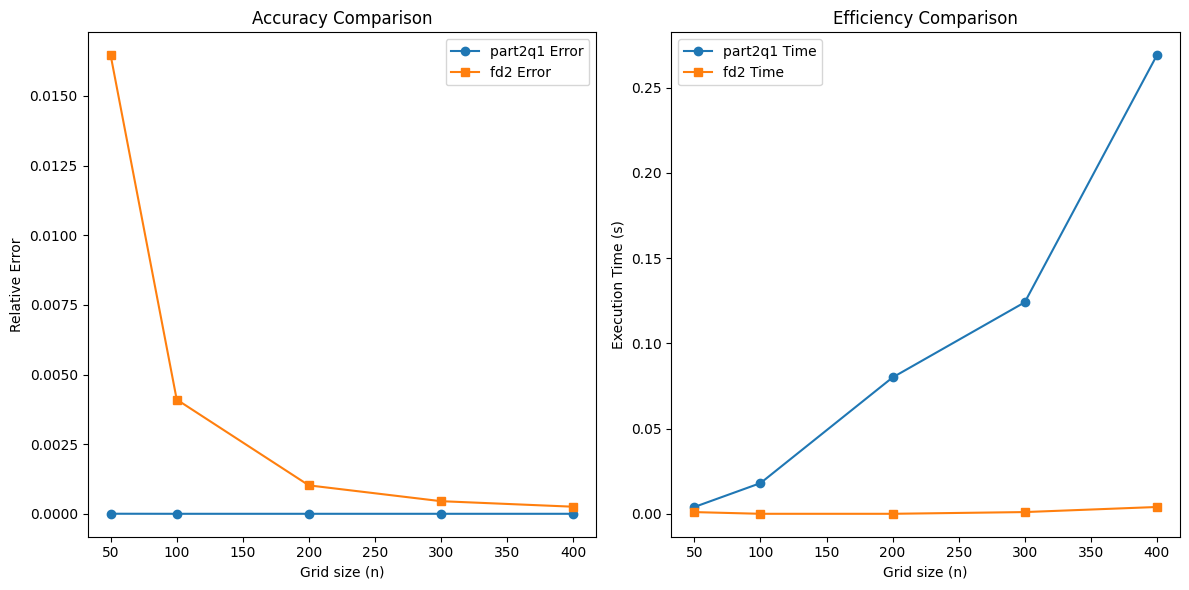

[(50,
  np.float64(2.1561762674691082e-06),
  np.float64(0.016462092083180807),
  0.0040018558502197266,
  0.000997781753540039),
 (100,
  np.float64(2.702060541929056e-08),
  np.float64(0.004101162002401954),
  0.01799917221069336,
  0.0),
 (200,
  np.float64(3.946354910842795e-10),
  np.float64(0.0010207264705658701),
  0.0800025463104248,
  0.0),
 (300,
  np.float64(3.408200522333233e-11),
  np.float64(0.00045280646541406085),
  0.12407588958740234,
  0.0010104179382324219),
 (400,
  np.float64(6.023049002899625e-12),
  np.float64(0.0002544467309963156),
  0.2690107822418213,
  0.003992557525634766)]

In [48]:
test_part2q1_vs_fd2()